In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

df = pd.read_csv("data/case1/train1.csv")
df["kilo_rpm"] = df["speed_rpm"] / 1000
df["delta_p"] = df["outlet_pressure_bar"] - df["inlet_pressure_bar"]
dataset = df[["power_w", "kilo_rpm", "delta_p", "flow_m3_h"]].copy()

target = "flow_m3_h"
feature_names = [column for column in dataset.columns if column != target]
X = dataset[feature_names].to_numpy(dtype=float)
y = dataset[target].to_numpy(dtype=float)

model = LinearRegression()
model.fit(X, y)

print([float(coef) for coef in model.coef_])
print(model.intercept_) 



[0.02150443022532821, 8.945707550746596, -36.289633436573276]
-0.4630948989429946


In [13]:
from sklearn.metrics import mean_squared_error, r2_score

test_df = pd.read_csv("data/case1/test1.csv")
test_df["kilo_rpm"] = test_df["speed_rpm"] / 1000
test_df["delta_p"] = (
    test_df["outlet_pressure_bar"] - test_df["inlet_pressure_bar"]
)

X_test = test_df[feature_names].to_numpy(dtype=float)
y_test = test_df[target].to_numpy(dtype=float)

predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print(f"Test MSE:  {mse:.3f}")
print(f"Test RMSE: {rmse:.3f} m³/h")
print(f"Test R²:   {r2:.3f}")

Test MSE:  12.505
Test RMSE: 3.536 m³/h
Test R²:   0.914


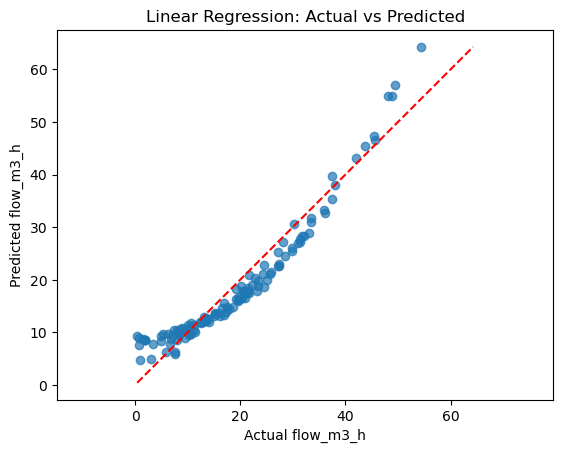

In [14]:
import matplotlib.pyplot as plt

plt.scatter(y_test, predictions, alpha=0.7)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual flow_m3_h")
plt.ylabel("Predicted flow_m3_h")
plt.title("Linear Regression: Actual vs Predicted")
plt.axis("equal")
plt.show()